# Laboratorium 2 - wieloręcy bandyci

## Przygotowanie

 * [opcjonalnie] Utwórz wirtualne środowisko
 `python3 -m venv ./recsyslab2`
 * zainstaluj potrzebne biblioteki:
 `pip3 install matplotlib`
 * upewnij się, że plik `bandit_framework.py` znajduje się w tym samym katalogu

## Część 1. - framework i naiwni bandyci

### Framework

Plik `bandit_framework.py` zawiera:
 * `Arm` - ramię o zadanym prawdopodobieństwie kliknięcia `click_probability`. Metoda `pull()` zwraca 1 (kliknięcie) lub 0. Bandyci **nie znają** tego prawdopodobieństwa - muszą się go nauczyć.
 * `Bandit` - klasa bazowa wszystkich algorytmów. Kontrakt:
   * `recommend(size)` zwraca listę **dokładnie** `size` **różnych** identyfikatorów ramion,
   * `feedback(arm_id, reward)` jest wywoływana po każdej rekomendacji **osobno dla każdego zarekomendowanego ramienia**, z nagrodą 0 lub 1.
 * `Runner` - przeprowadza symulację. W każdej epoce prosi bandytę o rekomendację, sprawdza jej poprawność (rozmiar, duplikaty, nieznane ramiona), pociąga każde zarekomendowane ramię i przekazuje bandycie wynik przez `feedback()`. Metoda `simulate()` zwraca listę obiektów `SimulationResult` (po jednym na bandytę) z nagrodą (reward) i regretem w każdej epoce.

Bandyci uczą się w trakcie symulacji, więc przed każdą nową symulacją trzeba ich utworzyć od nowa.

### Metryka - regret

Liczba kliknięć jest losowa i nie mówi wprost, jak daleko jesteśmy od ideału. Dlatego głównie patrzymy na **regret** - różnicę między oczekiwaną nagrodą najlepszej możliwej rekomendacji a oczekiwaną nagrodą rekomendacji bandyty:

$$\text{regret}_t = \sum_{a \in A^*} p_a - \sum_{a \in A_t} p_a$$

gdzie $A^*$ to zbiór ramion o najwyższym CTR, $A_t$ - rekomendacja bandyty w epoce $t$, a $p_a$ - prawdziwe prawdopodobieństwo kliknięcia ramienia $a$. Regret liczymy z prawdziwych prawdopodobieństw, więc nie zależy od szczęścia w losowaniu kliknięć.

Na wykresach pokazujemy **skumulowany regret** $\sum_{t} \text{regret}_t$:
 * jeśli rośnie liniowo - bandyta się nie uczy (albo wciąż płaci za eksplorację),
 * jeśli się wypłaszcza - bandyta znalazł najlepsze ramiona.

In [2]:
# importujemy wszystkie potrzebne pakiety

from dataclasses import dataclass
from random import sample, seed, shuffle, uniform
from typing import Tuple
from bandit_framework import *  # pakiet ze srodowiskiem testowym
import numpy as np

In [3]:
# inicjalizujemy parametry testu

seed(42)  # dla powtarzalnosci wynikow
epochs = 200
recommendation_size = 10

In [4]:
# inicjalizujemy ramiona bandytow
# ramiona dzielimy na grupy; CTR ramienia losujemy z przedzialu przypisanego do jego grupy
# nazwy ramion (np. top_3) sluza tylko nam do analizy wynikow - bandyci nie powinni z nich korzystac

class ArmTier(NamedTuple):
    name: str
    count: int
    ctr_range: Tuple[float, float]


def create_arms(tiers: List[ArmTier]) -> Dict[str, Arm]:
    all_arms = [Arm(f'{tier.name}_{i}', uniform(*tier.ctr_range)) for tier in tiers for i in range(tier.count)]
    shuffle(all_arms)
    return {arm.arm_id: arm for arm in all_arms}


tiers = [
    ArmTier('top', 5, (0.5, 0.7)),
    ArmTier('good', 15, (0.3, 0.5)),
    ArmTier('average', 50, (0.1, 0.3)),
    ArmTier('poor', 130, (0.0, 0.1)),
]
arms = create_arms(tiers)
arm_ids = list(arms.keys())

In [5]:
best_expected_reward = sum(sorted([arm.click_probability for arm in arms.values()], reverse=True)[:recommendation_size])
print(f'Number of arms: {len(arms)}')
print(f'Expected highest reward per epoch: {best_expected_reward:.2f}')

Number of arms: 200
Expected highest reward per epoch: 5.10


In [6]:
# pierwszy bandyta - wybiera losowe ramiona

class Random(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str]):
        super().__init__(bandit_id, arm_ids)

    def recommend(self, size: int) -> List[str]:
        return sample(self.arm_ids, size)

    def feedback(self, arm_id: str, reward: int) -> None:
        pass

In [7]:
# drugi bandyta (wyrocznia) korzysta z wiedzy, do ktorej przecietny bandyta nie ma dostepu

class Oracle(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], arms: Dict[str, Arm]):
        super().__init__(bandit_id, arm_ids)
        self.ranking = sorted(arm_ids, key=lambda arm_id: arms[arm_id].click_probability, reverse=True)

    def recommend(self, size: int) -> List[str]:
        return self.ranking[:size]

    def feedback(self, arm_id: str, reward: int) -> None:
        pass

In [8]:
# tworzymy liste bandytow do przetestowania

bandits = [
    Random('random', arm_ids),
    Oracle('oracle', arm_ids, arms)
]

In [9]:
# uruchamiamy test

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: random
Simulating: oracle

bandit                 total reward   total regret
oracle                         1022            0.0
random                          250          775.9


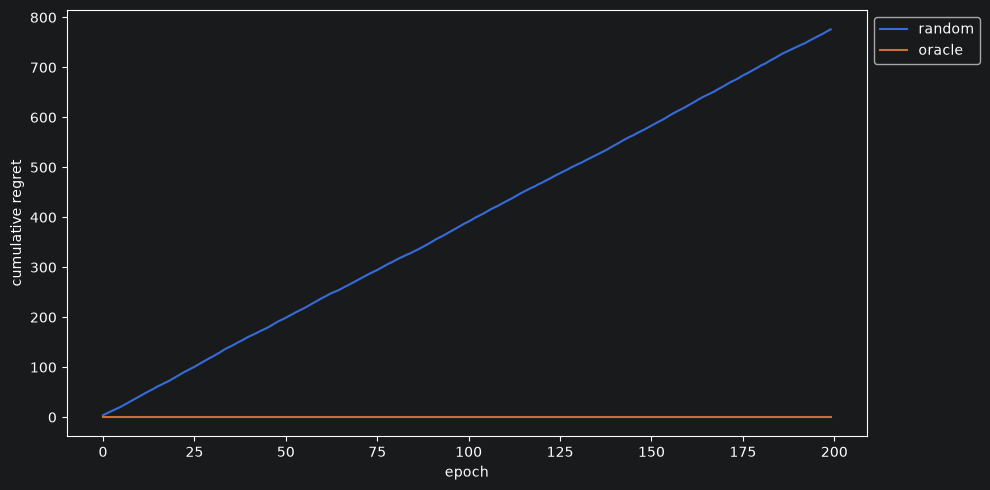

In [10]:
# skumulowany regret

runner.plot_results(results, mode='regret')

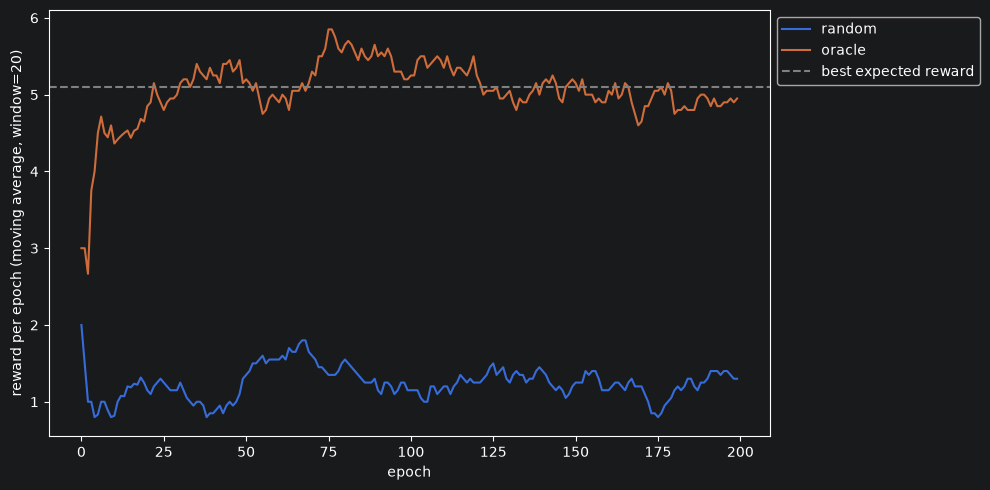

In [11]:
# reward (liczba klikniec) per epoka

runner.plot_results(results, mode='reward')

## Część 2. - ε-greedy

In [12]:
# statystyki, ktore bandyta zbiera o jednym ramieniu - uzyjemy ich we wszystkich bandytach

@dataclass
class ArmStats:
    trials: int = 0     # ile razy ramie bylo rekomendowane
    successes: int = 0  # ile razy zostalo klikniete

    @property
    def failures(self) -> int:
        return self.trials - self.successes

    @property
    def mean(self) -> float:  # srednia nagroda - empiryczny CTR
        return self.successes / self.trials if self.trials > 0 else 0.0

    def update(self, reward: int) -> None:
        self.trials += 1
        self.successes += reward

In [13]:
class EGreedy(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], epsilon: float):
        super().__init__(bandit_id, arm_ids)
        self.epsilon = epsilon
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}

    def recommend(self, size: int) -> List[str]:
        bandits_sorted = sorted(self.arm_ids, key=lambda arm_id: self.stats[arm_id].mean, reverse=True)

        bandits_random = self.arm_ids[:]
        shuffle(bandits_random)

        recommended_bandits = []
        recommended_bandits_set = set()
        current_idx = 0
        while len(recommended_bandits) < size:
            if random() > self.epsilon and bandits_sorted[current_idx] not in recommended_bandits_set:
                recommended_bandits.append(bandits_sorted[current_idx])
                recommended_bandits_set.add(bandits_sorted[current_idx])
            elif bandits_random[current_idx] not in recommended_bandits_set:
                recommended_bandits.append(bandits_random[current_idx])
                recommended_bandits_set.add(bandits_random[current_idx])
            current_idx += 1

        return recommended_bandits

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)

In [14]:
# porownujemy kilka wartosci epsilon

bandits = [EGreedy(f'egreedy_{epsilon}', arm_ids, epsilon) for epsilon in [0, 0.05, 0.25, 0.5]]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: egreedy_0
Simulating: egreedy_0.05
Simulating: egreedy_0.25
Simulating: egreedy_0.5

bandit                 total reward   total regret
egreedy_0.25                    593          408.6
egreedy_0.5                     526          491.8
egreedy_0.05                    467          563.5
egreedy_0                       237          775.0


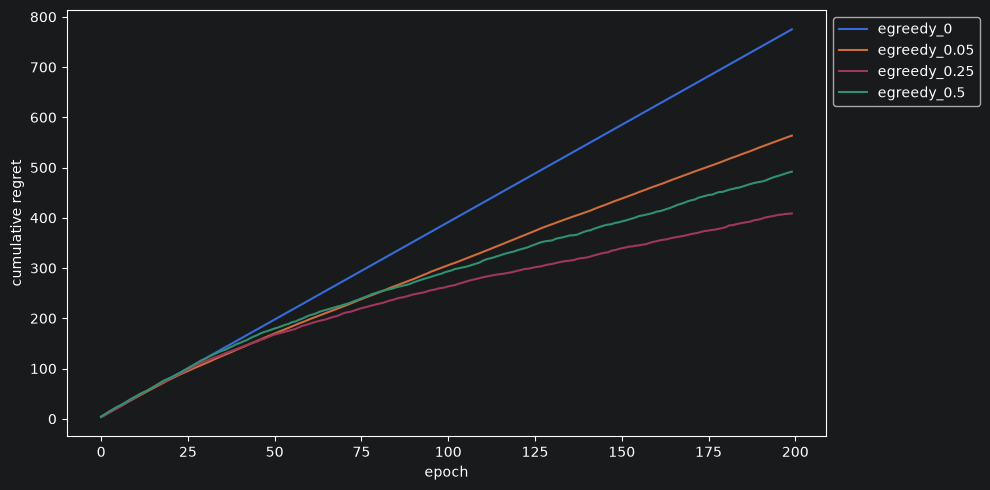

In [15]:
runner.plot_results(results, mode='regret')

In [16]:
# mozemy sprawdzic, jaka wiedze bandyta zdobyl o poszczegolnych ramionach

trained = next(bandit for bandit in bandits if bandit.bandit_id == 'egreedy_0.25')
top_arms = sorted(arm_ids, key=lambda arm_id: trained.stats[arm_id].mean, reverse=True)[:recommendation_size]

print(f"{'arm':<12}{'trials':>8}{'successes':>11}{'mean':>7}{'true CTR':>10}")
for arm_id in top_arms:
    stats = trained.stats[arm_id]
    print(f'{arm_id:<12}{stats.trials:>8}{stats.successes:>11}{stats.mean:>7.2f}{arms[arm_id].click_probability:>10.2f}')

arm           trials  successes   mean  true CTR
top_4            100         70   0.70      0.65
top_2             56         31   0.55      0.56
top_0             86         47   0.55      0.63
top_1            118         64   0.54      0.51
top_3             25         13   0.52      0.54
good_0           129         56   0.43      0.44
good_1            93         40   0.43      0.48
good_13          122         50   0.41      0.46
average_10        77         28   0.36      0.26
good_12           77         26   0.34      0.42


## Część 3. - UCB (Upper Confidence Bound)

In [27]:
class UCB(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], optimism_weight: float):
        super().__init__(bandit_id, arm_ids)
        self.optimism_weight = optimism_weight
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}

    def recommend(self, size: int) -> List[str]:
        total_impressions = sum([stat.trials for stat in self.stats.values()])

        bandit_scores = {}
        for arm_id, bandit_stats in self.stats.items():
            if self.stats[arm_id].trials == 0:
                bandit_scores[arm_id] = float('inf')
            else:
                bandit_scores[arm_id] = self.stats[arm_id].mean + self.optimism_weight * UCB.optimism(self.stats[arm_id].trials, total_impressions)

        return [str(x[0]) for x in sorted(bandit_scores.items(), key=lambda x: x[1], reverse=True)][:size]


    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)

    @staticmethod
    def optimism(bandit_trials: int, total_trials: int) -> float:
        if total_trials == 0:
            return float('inf')
        return np.sqrt(2 * np.log(total_trials) / bandit_trials)

In [28]:
bandits = [UCB(f'ucb_{optimism_weight}', arm_ids, optimism_weight) for optimism_weight in [0.01, 0.1, 0.3, 1]]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: ucb_0.01
Simulating: ucb_0.1
Simulating: ucb_0.3
Simulating: ucb_1

bandit                 total reward   total regret
ucb_0.1                         791          214.5
ucb_0.01                        663          324.6
ucb_0.3                         565          433.2
ucb_1                           321          701.9


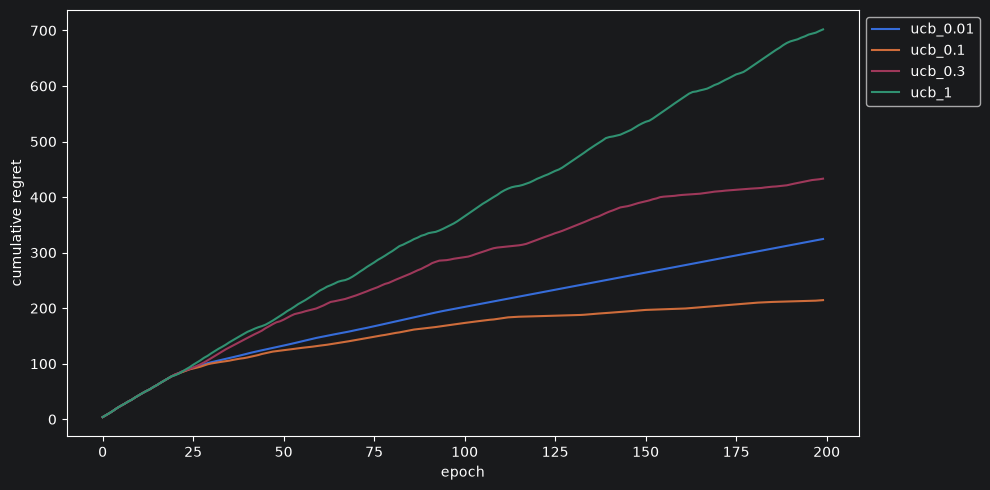

In [29]:
runner.plot_results(results, mode='regret')

## Część 4. - Thompson Sampling

In [36]:
class ThompsonSampling(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], reward_multiplier: float, regret_multiplier: float):
        super().__init__(bandit_id, arm_ids)
        self.reward_multiplier = reward_multiplier
        self.regret_multiplier = regret_multiplier
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}

    def recommend(self, size: int) -> List[str]:
        beta_results = {arm_id: np.random.beta(self.reward_multiplier * self.stats[arm_id].successes + 1, self.regret_multiplier * self.stats[arm_id].trials - self.stats[arm_id].successes + 1) for arm_id in self.stats.keys()}

        return [str(x[0]) for x in sorted(beta_results.items(), key=lambda x: x[1], reverse=True)][:size]

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)

In [37]:
bandits = [ThompsonSampling(f'ts_{reward_multiplier}_{regret_multiplier}', arm_ids, reward_multiplier, regret_multiplier)
           for reward_multiplier, regret_multiplier in [(1, 1), (10, 10), (1, 10), (10, 1)]]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: ts_1_1
Simulating: ts_10_10
Simulating: ts_1_10
Simulating: ts_10_1

bandit                 total reward   total regret
ts_10_1                         785          235.4
ts_10_10                        647          333.0
ts_1_1                          481          539.9
ts_1_10                         383          615.7


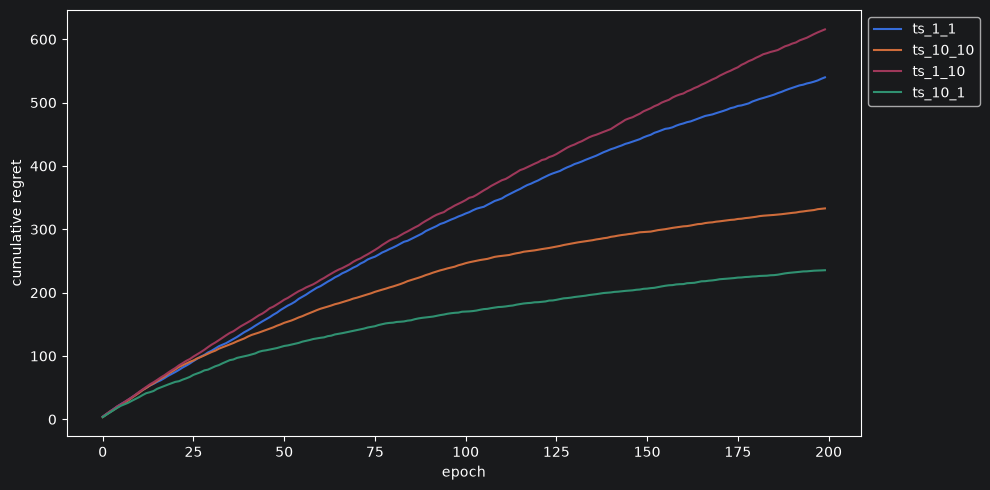

In [38]:
runner.plot_results(results, mode='regret')

## Część 5. - Własny bandyta

Zaimplementuj własny algorytm bandyty. Może to być np. bandyta Softmax, Thompson Sampling z dwoma rozkładami beta, Thompson Sampling z rozkładem innnym niż beta lub cokolwiek innego, co ci przyjdzie do głowy.

In [60]:
class NormalBandit(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], exploration_scale: float, random_state: int):
        super().__init__(bandit_id, arm_ids)
        self.exploration_scale = exploration_scale
        self.random_state = random_state
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}

    def recommend(self, size: int) -> List[str]:
        np.random.seed(self.random_state)

        means = {arm_id: (self.stats[arm_id].successes + 1) / (self.stats[arm_id].trials + 2) for arm_id in self.stats.keys()}
        variances = {arm_id: means[arm_id] * (1 - means[arm_id]) / (self.stats[arm_id].trials + 3) for arm_id in self.stats.keys()}
        
        normal_results = {arm_id: np.random.normal(means[arm_id], self.exploration_scale * np.sqrt(variances[arm_id])) for arm_id in self.stats.keys()}

        return [str(x[0]) for x in sorted(normal_results.items(), key=lambda x: x[1], reverse=True)][:size]

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)

In [61]:
bandits = [NormalBandit(f'normal_{i}', arm_ids, exploration_scale=i, random_state=1) for i in [0.1, 0.5, 1.0]]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: normal_0.1
Simulating: normal_0.5
Simulating: normal_1.0

bandit                 total reward   total regret
normal_1.0                      688          310.2
normal_0.1                      726          316.8
normal_0.5                      615          386.0


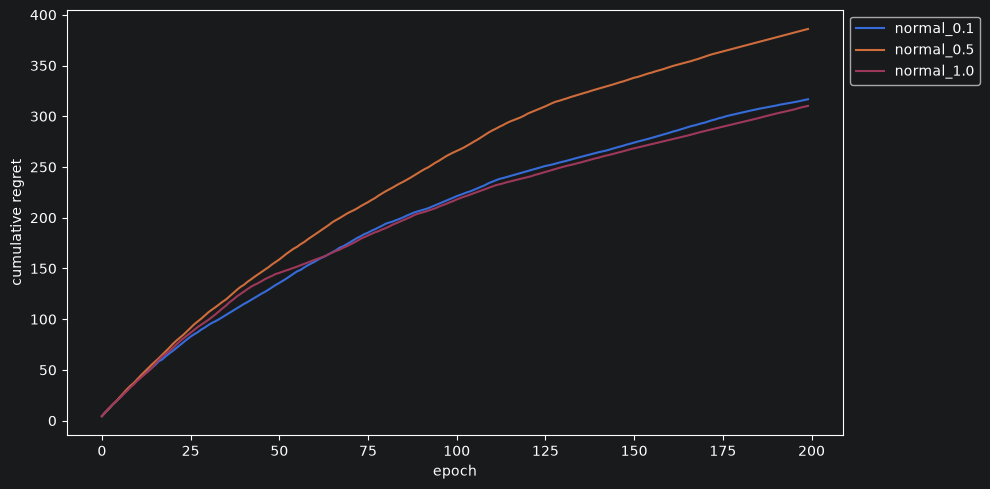

In [62]:
runner.plot_results(results, mode='regret')

## Część 6. - porównanie bandytów

In [63]:
# tworzymy nowych bandytow na potrzeby porowwnania
# mozesz wykorzystac parametry znalezione na wczesniejszych etapach lub przetestowac nowe
bandits = [
    Random('random', arm_ids),
    Oracle('oracle', arm_ids, arms),
    EGreedy('egreedy', arm_ids, epsilon=0.1),
    UCB('ucb', arm_ids, optimism_weight=1),
    ThompsonSampling('ts', arm_ids, reward_multiplier=1, regret_multiplier=1),
    NormalBandit('normal', arm_ids, exploration_scale=0.5, random_state=1)
]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: random
Simulating: oracle
Simulating: egreedy
Simulating: ucb
Simulating: ts
Simulating: normal

bandit                 total reward   total regret
oracle                         1013            0.0
normal                          683          329.7
egreedy                         569          426.3
ts                              554          496.3
ucb                             324          703.6
random                          243          767.2


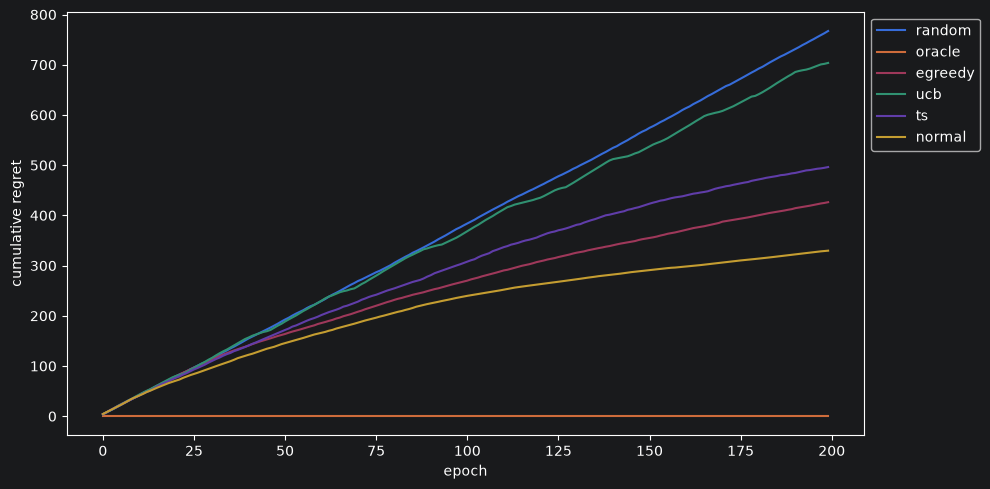

In [64]:
runner.plot_results(results, mode='regret')

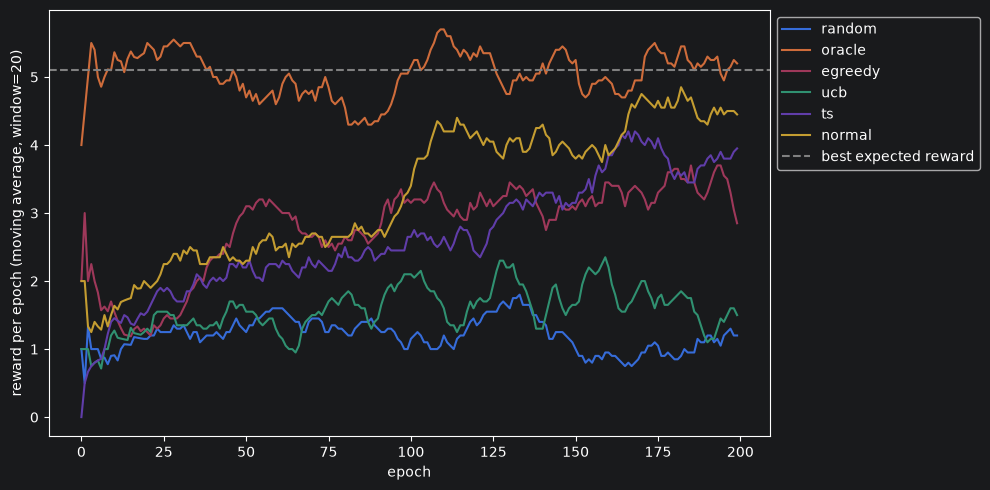

In [65]:
runner.plot_results(results, mode='reward')